# Netflix Content Analysis Using Python

## Project Overview
## Author: Banele Seko

This project performs exploratory data analysis (EDA) on a Netflix dataset to examine content types, release trends, popular genres, and movie runtimes.

### Objectives

- Compare Movies and TV Shows
- Analyze Netflix content growth over time
- Identify the top 10 genres
- Analyze movie runtime distribution
- Identify the top 10 release years
- Summarize key findings from the analysis

# 1. Importing Python Libraries

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

In [42]:
df = pd.read_csv("netflix_dataset.csv")

In [43]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 2. Data Inspection

Before analyzing the Netflix dataset, we inspect its structure, data types, summary statistics, and missing values.

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [45]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [46]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [47]:
df.duplicated().sum()

np.int64(0)

In [48]:
df.shape

(8807, 12)

## 3. Data Cleaning

The dataset is cleaned by handling missing values, checking for duplicates, and preparing the relevant columns for analysis.

In [49]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [50]:
df = df.drop_duplicates()

In [51]:
df.duplicated().sum()

np.int64(0)

In [52]:
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna("Unknown")

In [53]:
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

# Checking Cleaned data

In [54]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   str           
 1   type          8807 non-null   str           
 2   title         8807 non-null   str           
 3   director      8807 non-null   str           
 4   cast          8807 non-null   str           
 5   country       8807 non-null   str           
 6   date_added    8709 non-null   datetime64[us]
 7   release_year  8807 non-null   int64         
 8   rating        8807 non-null   str           
 9   duration      8804 non-null   str           
 10  listed_in     8807 non-null   str           
 11  description   8807 non-null   str           
dtypes: datetime64[us](1), int64(1), str(10)
memory usage: 825.8 KB


In [55]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


# Saving Cleaned data

In [56]:
df.to_csv("netflix_cleaned.csv", index=False)

## 4. Movies vs TV Shows

We compare the number of Movies and TV Shows available in the Netflix dataset.# 

In [57]:
df["type"].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

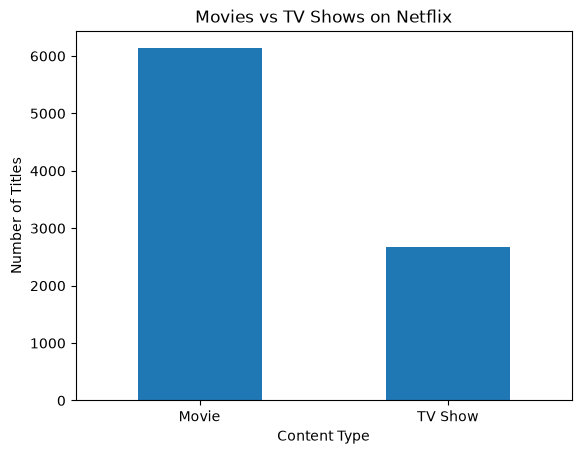

In [58]:
df["type"].value_counts().plot(
    kind="bar",
    title="Movies vs TV Shows on Netflix"
)

plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.show()


## 5. Content Growth Over Time

We analyze the number of Netflix titles released in each year to identify trends in content growth.

In [59]:
year_counts = df["release_year"].value_counts().sort_index()

year_counts.tail(15)

release_year
2007      88
2008     136
2009     152
2010     194
2011     185
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64

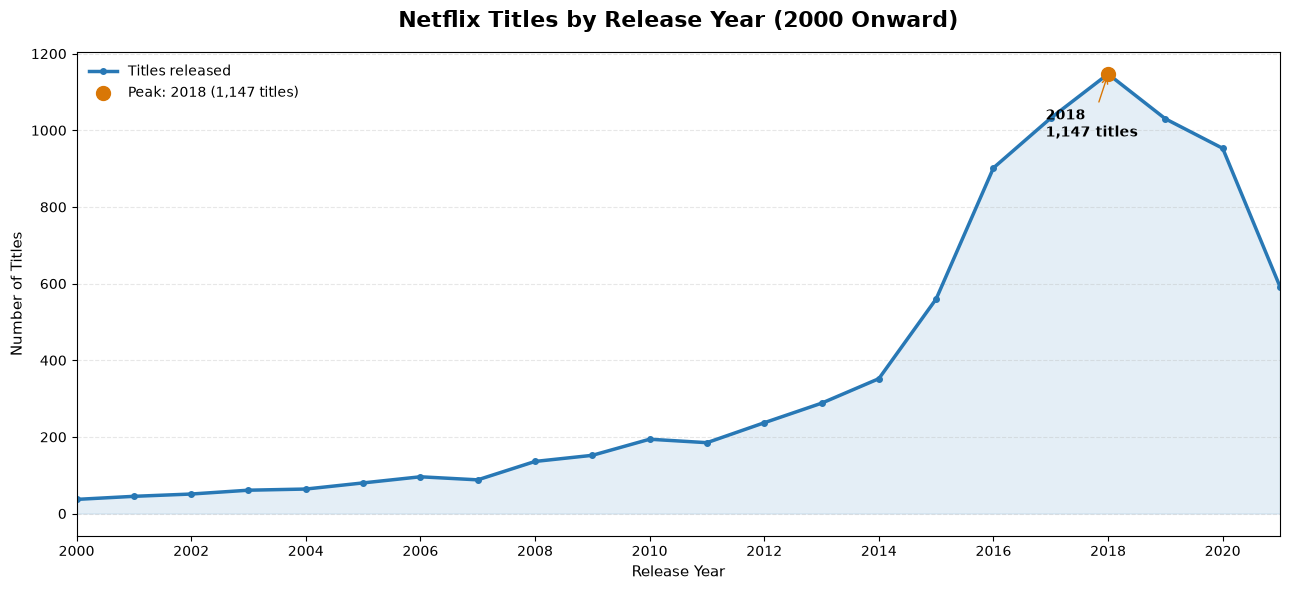

In [60]:
release_years = pd.to_numeric(df["release_year"], errors="coerce")

year_counts = (
    release_years.dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)


recent_years = year_counts[year_counts.index >= 2000]


peak_year = recent_years.idxmax()
peak_count = recent_years.max()


plt.figure(figsize=(13, 6))

plt.plot(
    recent_years.index,
    recent_years.values,
    color="#2878B5",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Titles released"
)

plt.fill_between(
    recent_years.index,
    recent_years.values,
    color="#2878B5",
    alpha=0.12
)


plt.scatter(
    peak_year,
    peak_count,
    color="#D97706",
    s=100,
    zorder=5,
    label=f"Peak: {peak_year} ({peak_count:,} titles)"
)

plt.annotate(
    f"{peak_year}\n{peak_count:,} titles",
    xy=(peak_year, peak_count),
    xytext=(-45, -45),
    textcoords="offset points",
    fontsize=10,
    fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="#D97706")
)

plt.title(
    "Netflix Titles by Release Year (2000 Onward)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Release Year", fontsize=11)
plt.ylabel("Number of Titles", fontsize=11)

plt.xticks(range(2000, int(recent_years.index.max()) + 1, 2))
plt.xlim(2000, int(recent_years.index.max()))

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

In [61]:
year_counts.idxmax(), year_counts.max()

(np.int64(2018), np.int64(1147))

## 6. Top 10 Genres

We analyze the genres/categories in the Netflix dataset and identify the 10 most common genres.

In [62]:
genre_series = df["listed_in"].str.split(", ")

In [63]:
genre_counts = genre_series.explode().value_counts()

In [64]:
genre_counts.head(10)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

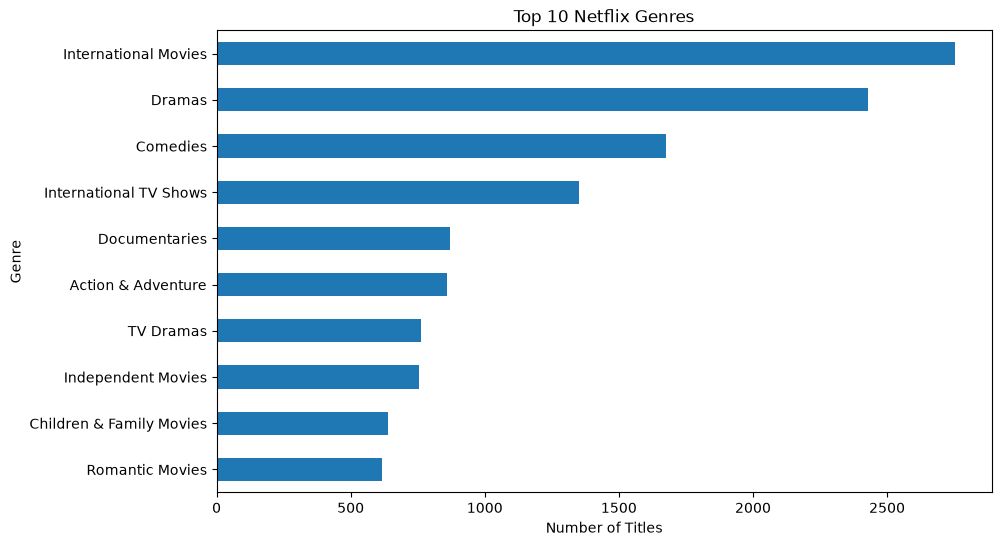

In [65]:
top_genres = genre_counts.head(10)

plt.figure(figsize=(10, 6))

top_genres.sort_values().plot(kind="barh")

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.show()

## 7. Movie Runtime Distribution

We analyze the distribution of movie runtimes to understand the typical length of Netflix movies.

In [66]:
movies = df[df["type"] == "Movie"].copy()

In [67]:
movies["runtime"] = movies["duration"].str.extract(r"(\d+)").astype(float)

In [68]:
movies[["title", "duration", "runtime"]].head()

,title,duration,runtime
0,Dick Johnson Is Dead,90 min,90.0
6,My Little Pony: A New Generation,91 min,91.0
7,Sankofa,125 min,125.0
9,The Starling,104 min,104.0
12,Je Suis Karl,127 min,127.0


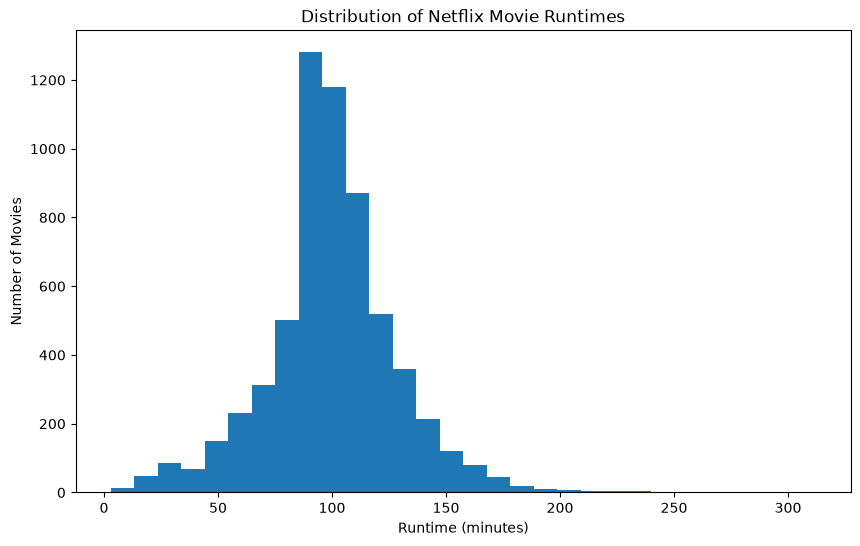

In [69]:
plt.figure(figsize=(10, 6))

plt.hist(movies["runtime"].dropna(), bins=30)

plt.title("Distribution of Netflix Movie Runtimes")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of Movies")

plt.show()

In [70]:
movies["runtime"].mean()

np.float64(99.57718668407311)

In [71]:
movies["runtime"].median()

np.float64(98.0)

## 8. Top 10 Release Years

We identify the 10 years with the highest number of Netflix titles released.

In [72]:
top_years = df["release_year"].value_counts().head(10)

top_years

release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64

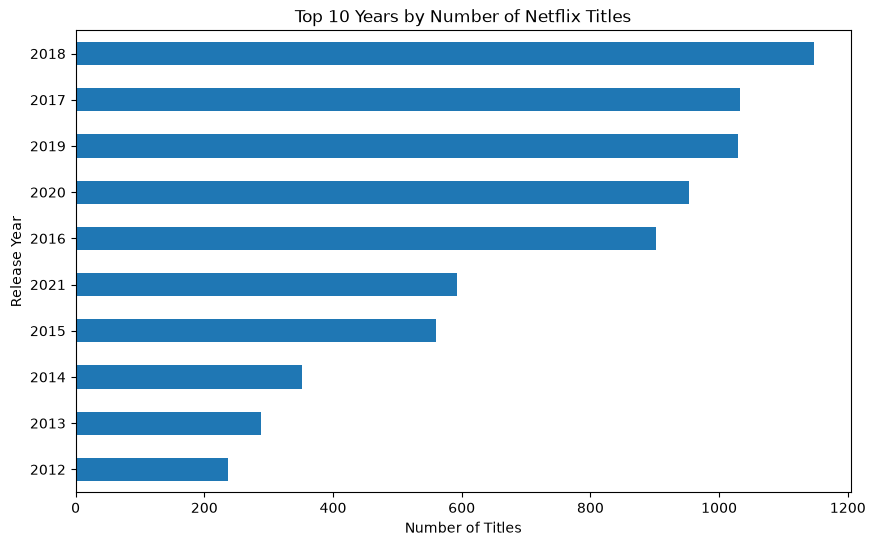

In [73]:
plt.figure(figsize=(10,6))

top_years.sort_values().plot(kind="barh")

plt.title("Top 10 Years by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Release Year")

plt.show()

In [74]:
content_by_year = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)

content_by_year.tail(15)

type,Movie,TV Show
release_year,,
2007,74,14
2008,113,23
2009,118,34
2010,154,40
2011,145,40
2012,173,64
2013,225,63
2014,264,88
2015,398,162


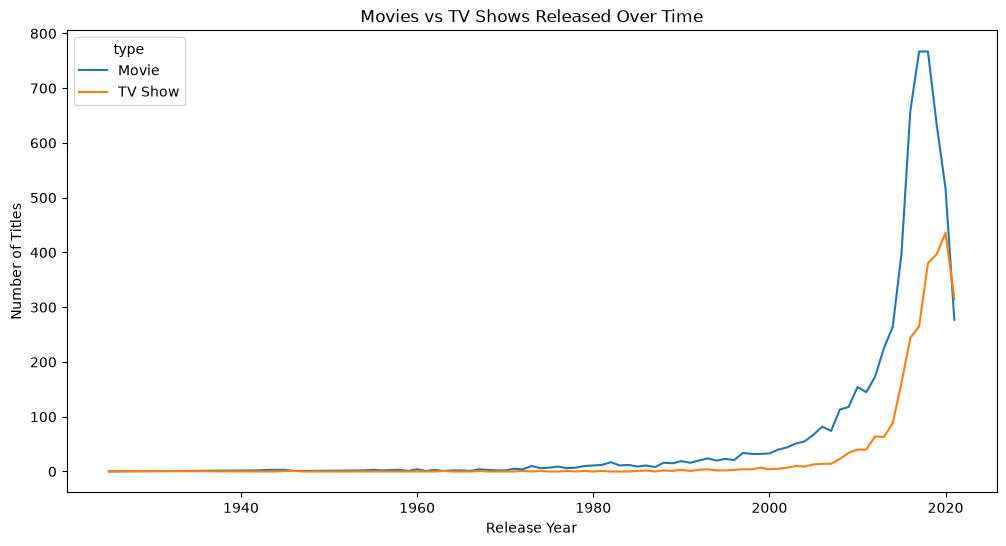

In [75]:
content_by_year.plot(figsize=(12, 6))

plt.title("Movies vs TV Shows Released Over Time")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

## 9. Key Insights and Conclusions

Based on the exploratory data analysis, the following insights were identified:

In [76]:
type_counts = df["type"].value_counts()

type_counts

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

In [77]:
peak_year = df["release_year"].value_counts().idxmax()
peak_year_count = df["release_year"].value_counts().max()

peak_year, peak_year_count

(np.int64(2018), np.int64(1147))

In [78]:
genre_counts.head(5)

listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64

In [79]:
movies["runtime"].mean()

np.float64(99.57718668407311)

In [80]:
movies["runtime"].median()

np.float64(98.0)

## 9. Key Insights and Conclusions

### Key Findings

- Movies make up the larger share of titles in the Netflix dataset compared with TV Shows.
- 2018 was the peak release year, with 1,147 titles.
- International Movies was the most common category, with 2,752 titles, followed by Dramas with 2,427 titles.
- The average movie runtime was approximately 99.58 minutes, while the median runtime was 98 minutes.
- Netflix content growth increased substantially from the 2000s onward, with Movies showing a particularly strong increase during the 2010s.